In [ ]:

# ==========================================
# AGENTICX PROJECT 1
# HANDWRITTEN CHARACTER RECOGNITION
# STEP 1: IMPORT LIBRARIES
# ==========================================

import os
import sys
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torchvision import datasets
from torch.utils.data import DataLoader, Subset

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

# GPU configuration
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("\nGPU AVAILABLE!")
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("\nGPU unavailable. Using CPU.")

print("Selected device:", device)


All libraries imported successfully!
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130

GPU AVAILABLE!
GPU Name: Tesla T4
Selected device: cuda


In [ ]:

# ==========================================
# STEP 2: PROJECT STRUCTURE
# ==========================================

PROJECT_DIR = "/content/AgenticX_Handwritten_Recognition"

folders = [
    "datasets",
    "models",
    "results",
    "results/graphs",
    "results/reports",
    "results/misclassified",
    "outputs"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print("Project folders created successfully!")

for folder in folders:
    print("Created:", folder)


Project folders created successfully!
Created: datasets
Created: models
Created: results
Created: results/graphs
Created: results/reports
Created: results/misclassified
Created: outputs


In [ ]:

# ==========================================
# STEP 3: ENVIRONMENT VERIFICATION
# ==========================================

print("PROJECT:", PROJECT_DIR)
print("DEVICE:", device)
print("CUDA AVAILABLE:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU MEMORY:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")

print("\nEnvironment ready for development!")


PROJECT: /content/AgenticX_Handwritten_Recognition
DEVICE: cuda
CUDA AVAILABLE: True
GPU MEMORY: 14.56 GB

Environment ready for development!


In [ ]:

# ==========================================
# STEP 5: DOWNLOAD DATASETS
# ==========================================

from torchvision import datasets, transforms
from PIL import Image

DATA_DIR = os.path.join(PROJECT_DIR, "datasets")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# MNIST preprocessing
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# EMNIST preprocessing
# Transpose corrects the stored image orientation
emnist_transform = transforms.Compose([
    transforms.Lambda(
        lambda img: img.transpose(Image.Transpose.TRANSPOSE)
    ),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

print("Downloading MNIST...")

mnist_train = datasets.MNIST(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=mnist_transform
)

mnist_test = datasets.MNIST(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=mnist_transform
)

print("\nDownloading EMNIST ByClass...")

emnist_train = datasets.EMNIST(
    root=DATA_DIR,
    split="byclass",
    train=True,
    download=True,
    transform=emnist_transform
)

emnist_test = datasets.EMNIST(
    root=DATA_DIR,
    split="byclass",
    train=False,
    download=True,
    transform=emnist_transform
)

print("\n========== DATASET SUMMARY ==========")

print("MNIST Training:", len(mnist_train))
print("MNIST Testing:", len(mnist_test))

print("EMNIST Training:", len(emnist_train))
print("EMNIST Testing:", len(emnist_test))

print("EMNIST Classes:", len(emnist_train.classes))
print("Class Labels:", emnist_train.classes)

print("\nDATASETS DOWNLOADED SUCCESSFULLY!")




========== DATASET SUMMARY ==========
MNIST Training: 60000
MNIST Testing: 10000
EMNIST Training: 697932
EMNIST Testing: 116323
EMNIST Classes: 62
Class Labels: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']

DATASETS DOWNLOADED SUCCESSFULLY!


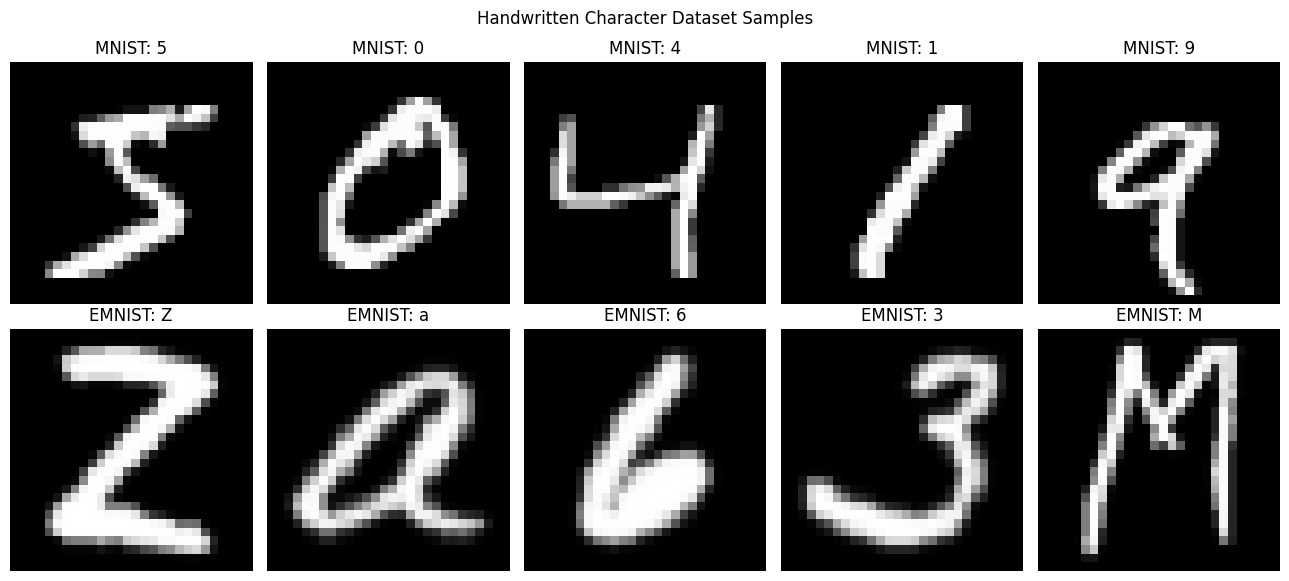

In [ ]:

# ==========================================
# STEP 6: VISUALIZE DATASETS
# ==========================================

fig, axes = plt.subplots(2, 5, figsize=(13, 6))

# MNIST samples
for i in range(5):
    image, label = mnist_train[i]

    axes[0, i].imshow(
        image.squeeze().numpy(),
        cmap="gray"
    )
    axes[0, i].set_title(f"MNIST: {label}")
    axes[0, i].axis("off")

# EMNIST samples
for i in range(5):
    image, label = emnist_train[i]

    axes[1, i].imshow(
        image.squeeze().numpy(),
        cmap="gray"
    )

    axes[1, i].set_title(
        f"EMNIST: {emnist_train.classes[label]}"
    )
    axes[1, i].axis("off")

plt.suptitle("Handwritten Character Dataset Samples")
plt.tight_layout()
plt.show()


In [ ]:

# ==========================================
# STEP 7: CREATE DATALOADERS
# ==========================================

BATCH_SIZE = 128

mnist_train_loader = DataLoader(
    mnist_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

mnist_test_loader = DataLoader(
    mnist_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

emnist_train_loader = DataLoader(
    emnist_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

emnist_test_loader = DataLoader(
    emnist_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("MNIST batches:", len(mnist_train_loader))
print("EMNIST batches:", len(emnist_train_loader))
print("Batch size:", BATCH_SIZE)
print("DataLoaders created successfully!")


MNIST batches: 469
EMNIST batches: 5453
Batch size: 128
DataLoaders created successfully!


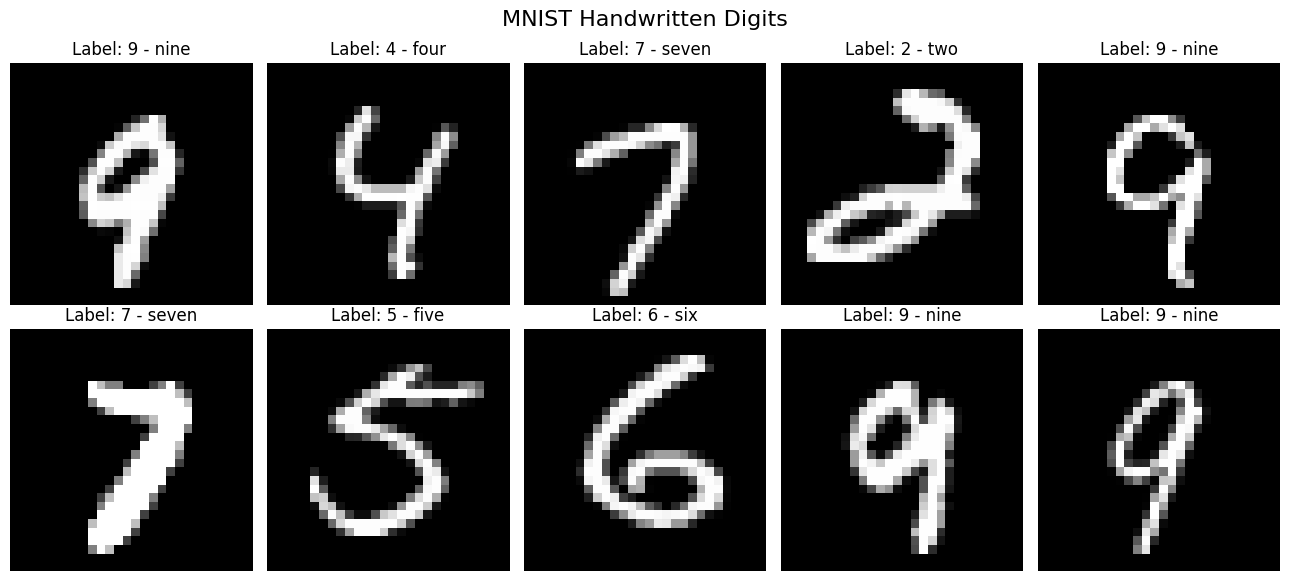

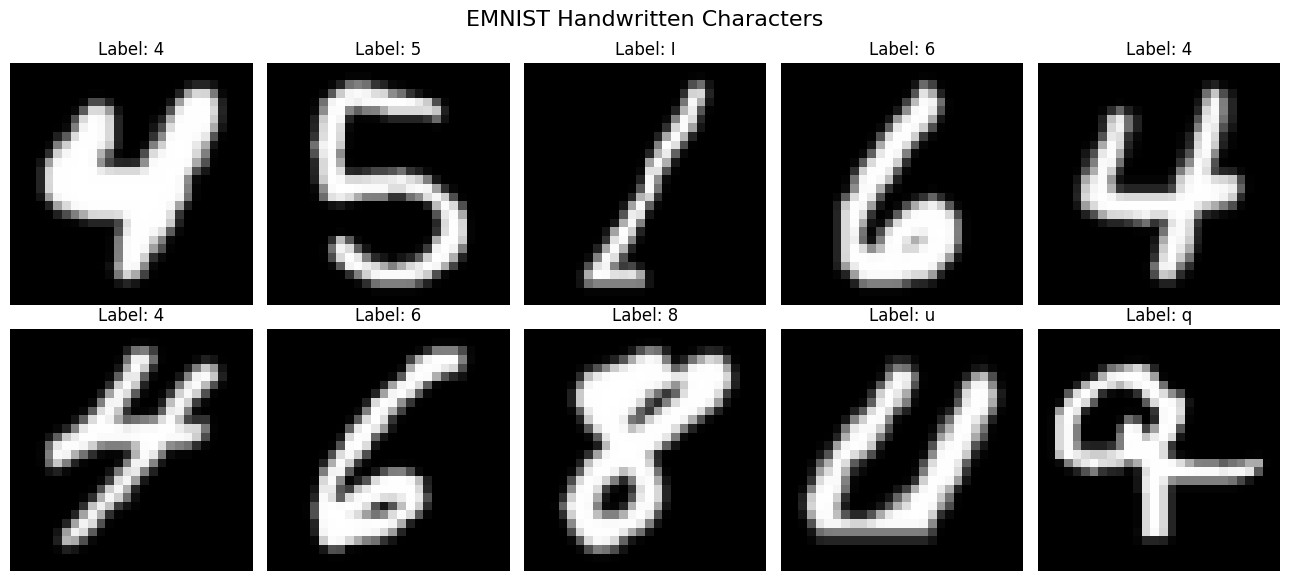

Dataset visual inspection completed!


In [ ]:

# ==========================================
# STEP 8: DATASET VISUAL INSPECTION
# ==========================================

import matplotlib.pyplot as plt
import random

def show_samples(dataset, title, count=10):
    indices = random.sample(range(len(dataset)), count)

    fig, axes = plt.subplots(2, 5, figsize=(13, 6))
    axes = axes.flatten()

    for ax, idx in zip(axes, indices):
        image, label = dataset[idx]

        # Reverse normalization for visualization
        image = image.squeeze().numpy()
        image = image * 0.5 + 0.5

        ax.imshow(image, cmap="gray")
        ax.set_title(f"Label: {dataset.classes[label]}"
                     if hasattr(dataset, "classes")
                     else f"Label: {label}")
        ax.axis("off")

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()


show_samples(mnist_train, "MNIST Handwritten Digits")
show_samples(emnist_train, "EMNIST Handwritten Characters")

print("Dataset visual inspection completed!")


In [ ]:

# ==========================================
# STEP 9: PREPARE SVM DATASET
# ==========================================

from skimage.feature import hog
from tqdm.auto import tqdm

# Reproducible subsets
rng = np.random.default_rng(42)

train_indices = rng.choice(
    len(mnist_train),
    size=15000,
    replace=False
)

test_indices = rng.choice(
    len(mnist_test),
    size=3000,
    replace=False
)

def extract_hog_features(dataset, indices):
    features = []
    labels = []

    for idx in tqdm(indices, desc="Extracting HOG"):
        image, label = dataset[idx]

        # Undo normalization
        image = image.squeeze().numpy()
        image = image * 0.5 + 0.5

        feature = hog(
            image,
            orientations=9,
            pixels_per_cell=(4, 4),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        features.append(feature)
        labels.append(label)

    return np.array(features), np.array(labels)


X_train_hog, y_train_hog = extract_hog_features(
    mnist_train, train_indices
)

X_test_hog, y_test_hog = extract_hog_features(
    mnist_test, test_indices
)

print("\nHOG FEATURE EXTRACTION COMPLETED")
print("Training shape:", X_train_hog.shape)
print("Testing shape:", X_test_hog.shape)


Extracting HOG:   0%|          | 0/15000 [00:00<?, ?it/s]

Extracting HOG:   0%|          | 0/3000 [00:00<?, ?it/s]


HOG FEATURE EXTRACTION COMPLETED
Training shape: (15000, 1296)
Testing shape: (3000, 1296)


In [ ]:

# ==========================================
# STEP 10: TRAIN SVM BASELINE
# ==========================================

svm_model = LinearSVC(
    C=1.0,
    max_iter=3000,
    dual="auto",
    random_state=42
)

start_time = time.perf_counter()

svm_model.fit(X_train_hog, y_train_hog)

svm_training_time = time.perf_counter() - start_time

print("SVM training completed!")
print("Training time:", round(svm_training_time, 2), "seconds")


SVM training completed!
Training time: 4.93 seconds


In [ ]:

# ==========================================
# STEP 11: SVM EVALUATION
# ==========================================

start_time = time.perf_counter()

svm_predictions = svm_model.predict(X_test_hog)

svm_inference_time = (
    time.perf_counter() - start_time
)

svm_accuracy = accuracy_score(
    y_test_hog,
    svm_predictions
)

print("========== SVM RESULTS ==========")

print("Accuracy:",
      round(svm_accuracy * 100, 2), "%")

print("Training time:",
      round(svm_training_time, 2), "seconds")

print("Total inference time:",
      round(svm_inference_time, 4), "seconds")

print("Average inference per image:",
      round(svm_inference_time / len(X_test_hog) * 1000, 4),
      "ms")

print("\nClassification Report:")
print(classification_report(
    y_test_hog,
    svm_predictions,
    zero_division=0
))


========== SVM RESULTS ==========
Accuracy: 97.63 %
Training time: 4.93 seconds
Total inference time: 0.0359 seconds
Average inference per image: 0.012 ms

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       320
           1       0.99      0.99      0.99       319
           2       0.98      0.98      0.98       310
           3       0.95      0.99      0.97       306
           4       0.97      0.98      0.98       275
           5       0.97      0.96      0.96       266
           6       0.99      0.99      0.99       281
           7       0.97      0.97      0.97       311
           8       0.96      0.97      0.97       299
           9       0.98      0.95      0.97       313

    accuracy                           0.98      3000
   macro avg       0.98      0.98      0.98      3000
weighted avg       0.98      0.98      0.98      3000



In [ ]:

# ==========================================
# STEP 12: SAVE SVM RESULTS
# ==========================================

import joblib

svm_results = {
    "Model": "HOG + Linear SVM",
    "Dataset": "MNIST",
    "Training Samples": len(X_train_hog),
    "Testing Samples": len(X_test_hog),
    "Accuracy (%)": round(svm_accuracy * 100, 2),
    "Training Time (seconds)": round(svm_training_time, 4),
    "Inference Time (seconds)": round(svm_inference_time, 4),
    "Inference Per Image (ms)": round(
        svm_inference_time / len(X_test_hog) * 1000, 4
    )
}

svm_results_df = pd.DataFrame([svm_results])

display(svm_results_df)

svm_path = os.path.join(
    PROJECT_DIR, "models", "mnist_svm.pkl"
)

joblib.dump(svm_model, svm_path)

svm_results_df.to_csv(
    os.path.join(
        PROJECT_DIR, "results", "svm_baseline.csv"
    ),
    index=False
)

print("SVM model and results saved successfully!")


,Model,Dataset,Training Samples,Testing Samples,Accuracy (%),Training Time (seconds),Inference Time (seconds),Inference Per Image (ms)
0,HOG + Linear SVM,MNIST,15000,3000,97.63,4.9327,0.0359,0.012


SVM model and results saved successfully!


In [ ]:

# ==========================================
# STEP 13: CNN ARCHITECTURE
# ==========================================

class HandwritingCNN(nn.Module):

    def __init__(self, num_classes):
        super(HandwritingCNN, self).__init__()

        self.features = nn.Sequential(

            # Convolution Block 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolution Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolution Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Create two separate models

mnist_model = HandwritingCNN(num_classes=10).to(device)

emnist_model = HandwritingCNN(num_classes=62).to(device)

print("CNN architecture created successfully!")

print("\nMNIST output classes:", 10)
print("EMNIST output classes:", 62)

print("\nMNIST parameters:",
      sum(p.numel() for p in mnist_model.parameters()))

print("EMNIST parameters:",
      sum(p.numel() for p in emnist_model.parameters()))


CNN architecture created successfully!

MNIST output classes: 10
EMNIST output classes: 62

MNIST parameters: 1701578
EMNIST parameters: 1714942


In [ ]:

# ==========================================
# STEP 14: TRAINING DATA PREPARATION
# ==========================================

from torch.utils.data import random_split

# MNIST: all training images
mnist_cnn_train_loader = DataLoader(
    mnist_train,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# EMNIST: reproducible 150k subset
rng = np.random.default_rng(42)

emnist_indices = rng.choice(
    len(emnist_train),
    size=150000,
    replace=False
)

emnist_subset = Subset(
    emnist_train,
    emnist_indices.tolist()
)

train_size = 135000
val_size = 15000

emnist_train_split, emnist_val_split = random_split(
    emnist_subset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

emnist_cnn_train_loader = DataLoader(
    emnist_train_split,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

emnist_cnn_val_loader = DataLoader(
    emnist_val_split,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("MNIST training images:", len(mnist_train))
print("EMNIST training images:", len(emnist_train_split))
print("EMNIST validation images:", len(emnist_val_split))
print("EMNIST testing images:", len(emnist_test))


MNIST training images: 60000
EMNIST training images: 135000
EMNIST validation images: 15000
EMNIST testing images: 116323


In [ ]:

# ==========================================
# STEP 15: TRAINING FUNCTIONS
# ==========================================

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100 * correct / total


@torch.no_grad()
def evaluate_model(model, loader, criterion):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)

        loss = criterion(outputs, labels)

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, 100 * correct / total


def train_model(model, train_loader, val_loader,
                model_name, epochs=3):

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    print(f"\nTraining {model_name}")
    print("=" * 45)

    for epoch in range(epochs):

        start = time.perf_counter()

        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer
        )

        val_loss, val_acc = evaluate_model(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_acc)

        elapsed = time.perf_counter() - start

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Acc: {val_acc:.2f}% | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

    return history


In [ ]:

# ==========================================
# STEP 16: TRAIN MNIST CNN
# ==========================================

mnist_train_split, mnist_val_split = random_split(
    mnist_train,
    [54000, 6000],
    generator=torch.Generator().manual_seed(42)
)

mnist_train_loader = DataLoader(
    mnist_train_split,
    batch_size=128,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

mnist_val_loader = DataLoader(
    mnist_val_split,
    batch_size=128,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

mnist_history = train_model(
    model=mnist_model,
    train_loader=mnist_train_loader,
    val_loader=mnist_val_loader,
    model_name="MNIST CNN",
    epochs=3
)

# Save trained model
torch.save(
    mnist_model.state_dict(),
    os.path.join(PROJECT_DIR, "models", "mnist_cnn.pth")
)

print("\nMNIST CNN training completed and model saved!")



Training MNIST CNN
Epoch 1/3 | Train Acc: 96.20% | Val Acc: 98.32% | Train Loss: 0.1196 | Val Loss: 0.0598 | Time: 14.9s
Epoch 2/3 | Train Acc: 98.32% | Val Acc: 98.70% | Train Loss: 0.0531 | Val Loss: 0.0446 | Time: 14.6s
Epoch 3/3 | Train Acc: 98.87% | Val Acc: 98.85% | Train Loss: 0.0375 | Val Loss: 0.0420 | Time: 14.7s

MNIST CNN training completed and model saved!


In [ ]:

# ==========================================
# STEP 17: TRAIN EMNIST CNN
# ==========================================

emnist_history = train_model(
    model=emnist_model,
    train_loader=emnist_cnn_train_loader,
    val_loader=emnist_cnn_val_loader,
    model_name="EMNIST ByClass CNN",
    epochs=3
)

# Save trained model
torch.save(
    emnist_model.state_dict(),
    os.path.join(PROJECT_DIR, "models", "emnist_cnn.pth")
)

print("\nEMNIST CNN training completed and model saved!")



Training EMNIST ByClass CNN
Epoch 1/3 | Train Acc: 78.01% | Val Acc: 84.21% | Train Loss: 0.6949 | Val Loss: 0.4573 | Time: 35.3s
Epoch 2/3 | Train Acc: 83.22% | Val Acc: 85.24% | Train Loss: 0.4846 | Val Loss: 0.4222 | Time: 36.8s
Epoch 3/3 | Train Acc: 84.39% | Val Acc: 85.75% | Train Loss: 0.4427 | Val Loss: 0.3985 | Time: 36.7s

EMNIST CNN training completed and model saved!


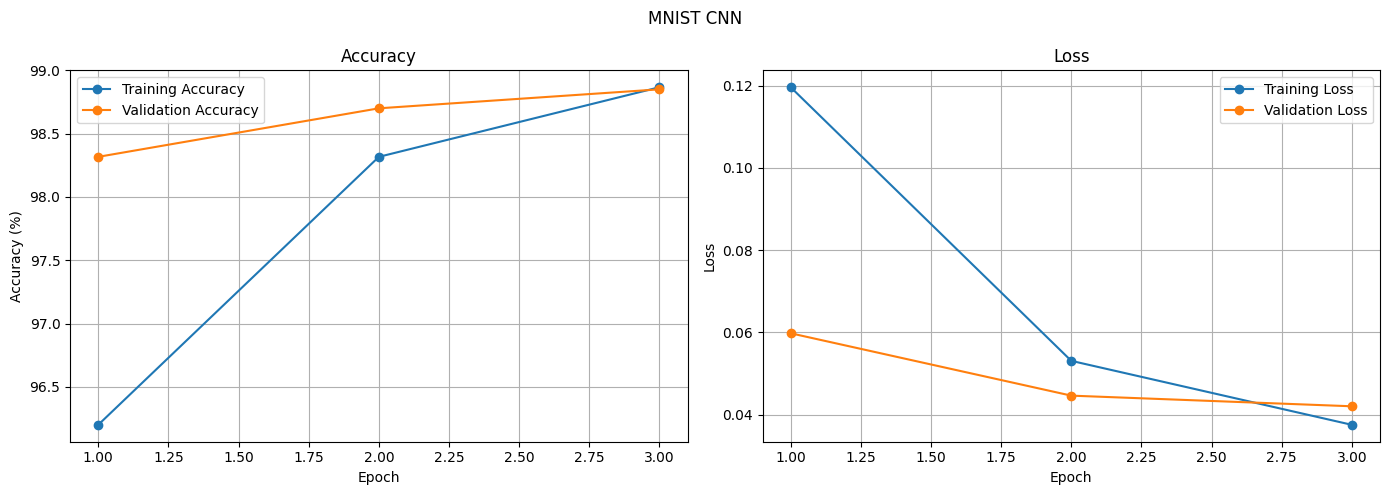

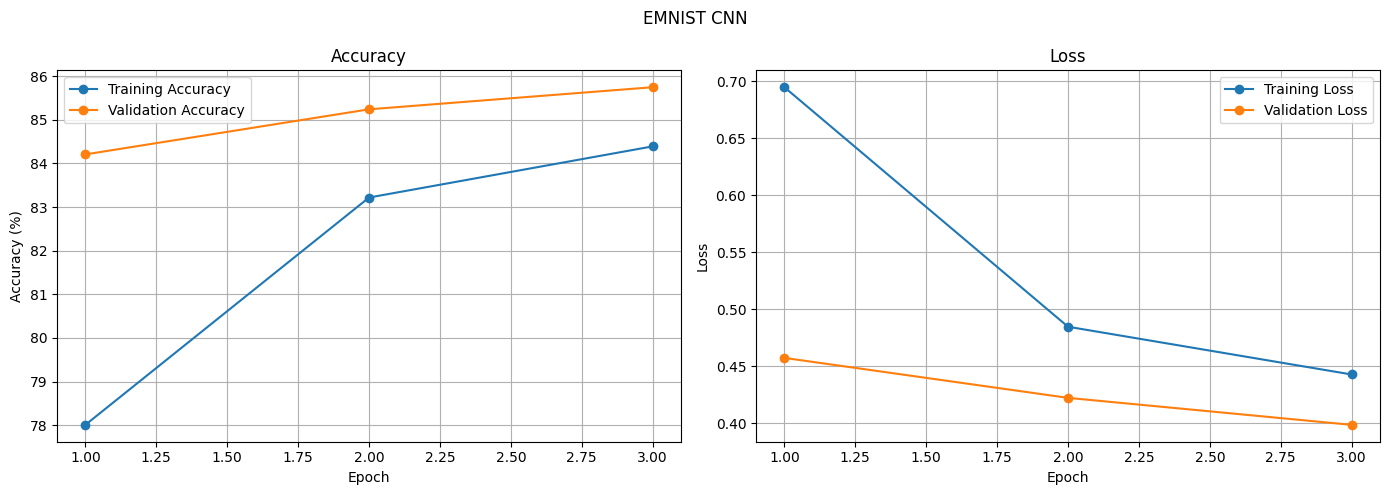

Training graphs saved successfully!


In [ ]:

# ==========================================
# STEP 18: TRAINING CURVES
# ==========================================

def plot_training_history(history, model_name):

    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy
    axes[0].plot(
        epochs, history["train_accuracy"],
        marker="o", label="Training Accuracy"
    )

    axes[0].plot(
        epochs, history["val_accuracy"],
        marker="o", label="Validation Accuracy"
    )

    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].legend()
    axes[0].grid(True)

    # Loss
    axes[1].plot(
        epochs, history["train_loss"],
        marker="o", label="Training Loss"
    )

    axes[1].plot(
        epochs, history["val_loss"],
        marker="o", label="Validation Loss"
    )

    axes[1].set_title("Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True)

    plt.suptitle(model_name)
    plt.tight_layout()

    filename = model_name.lower().replace(" ", "_") + "_curves.png"

    plt.savefig(
        os.path.join(PROJECT_DIR, "results", "graphs", filename),
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()


plot_training_history(mnist_history, "MNIST CNN")
plot_training_history(emnist_history, "EMNIST CNN")

print("Training graphs saved successfully!")


In [ ]:

# ==========================================
# STEP 19: FINAL TEST EVALUATION
# ==========================================

mnist_criterion = nn.CrossEntropyLoss()

mnist_test_loss, mnist_test_accuracy = evaluate_model(
    mnist_model,
    mnist_test_loader,
    mnist_criterion
)

emnist_test_loss, emnist_test_accuracy = evaluate_model(
    emnist_model,
    emnist_test_loader,
    mnist_criterion
)

results = pd.DataFrame([
    {
        "Model": "HOG + SVM",
        "Dataset": "MNIST",
        "Accuracy (%)": svm_accuracy * 100
    },
    {
        "Model": "CNN",
        "Dataset": "MNIST",
        "Accuracy (%)": mnist_test_accuracy
    },
    {
        "Model": "CNN",
        "Dataset": "EMNIST ByClass",
        "Accuracy (%)": emnist_test_accuracy
    }
])

display(results.round(2))

results.to_csv(
    os.path.join(PROJECT_DIR, "results", "model_comparison.csv"),
    index=False
)

print("Final test evaluation completed!")


,Model,Dataset,Accuracy (%)
0,HOG + SVM,MNIST,97.63
1,CNN,MNIST,99.17
2,CNN,EMNIST ByClass,85.66


Final test evaluation completed!



MNIST CNN
Total misclassified: 83
Displaying: 20


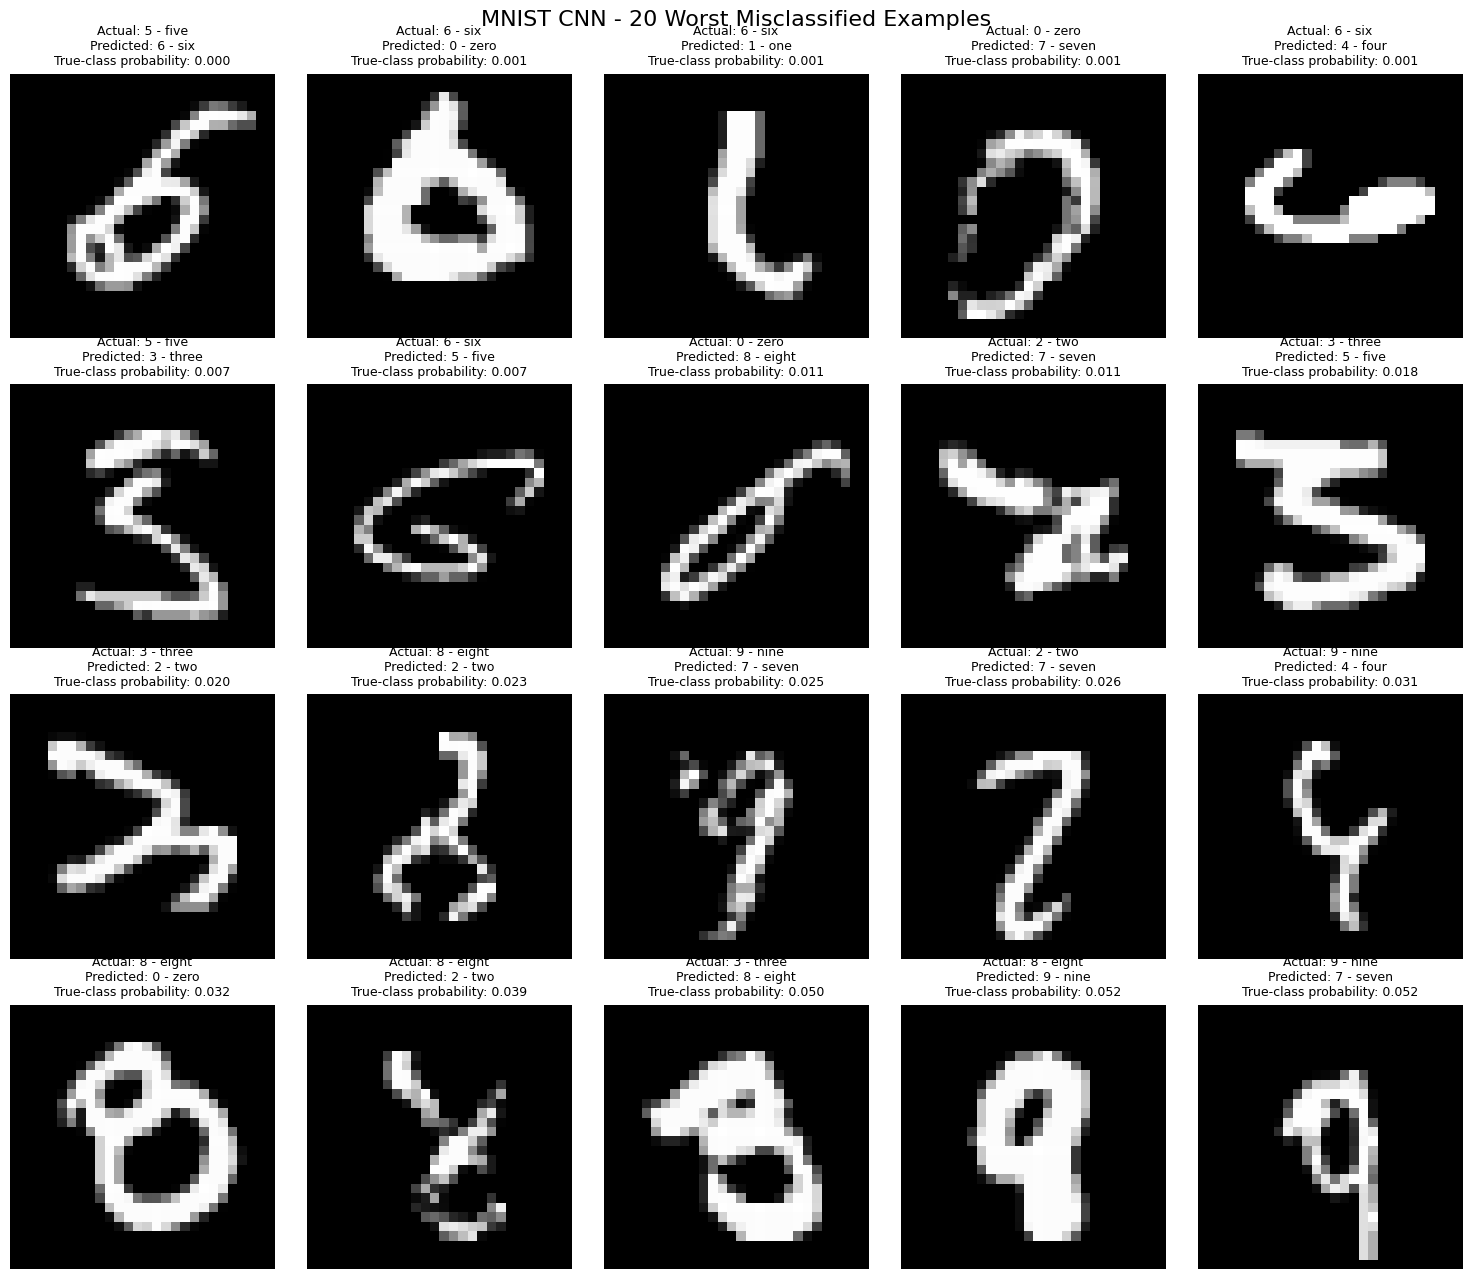


EMNIST CNN
Total misclassified: 16677
Displaying: 20


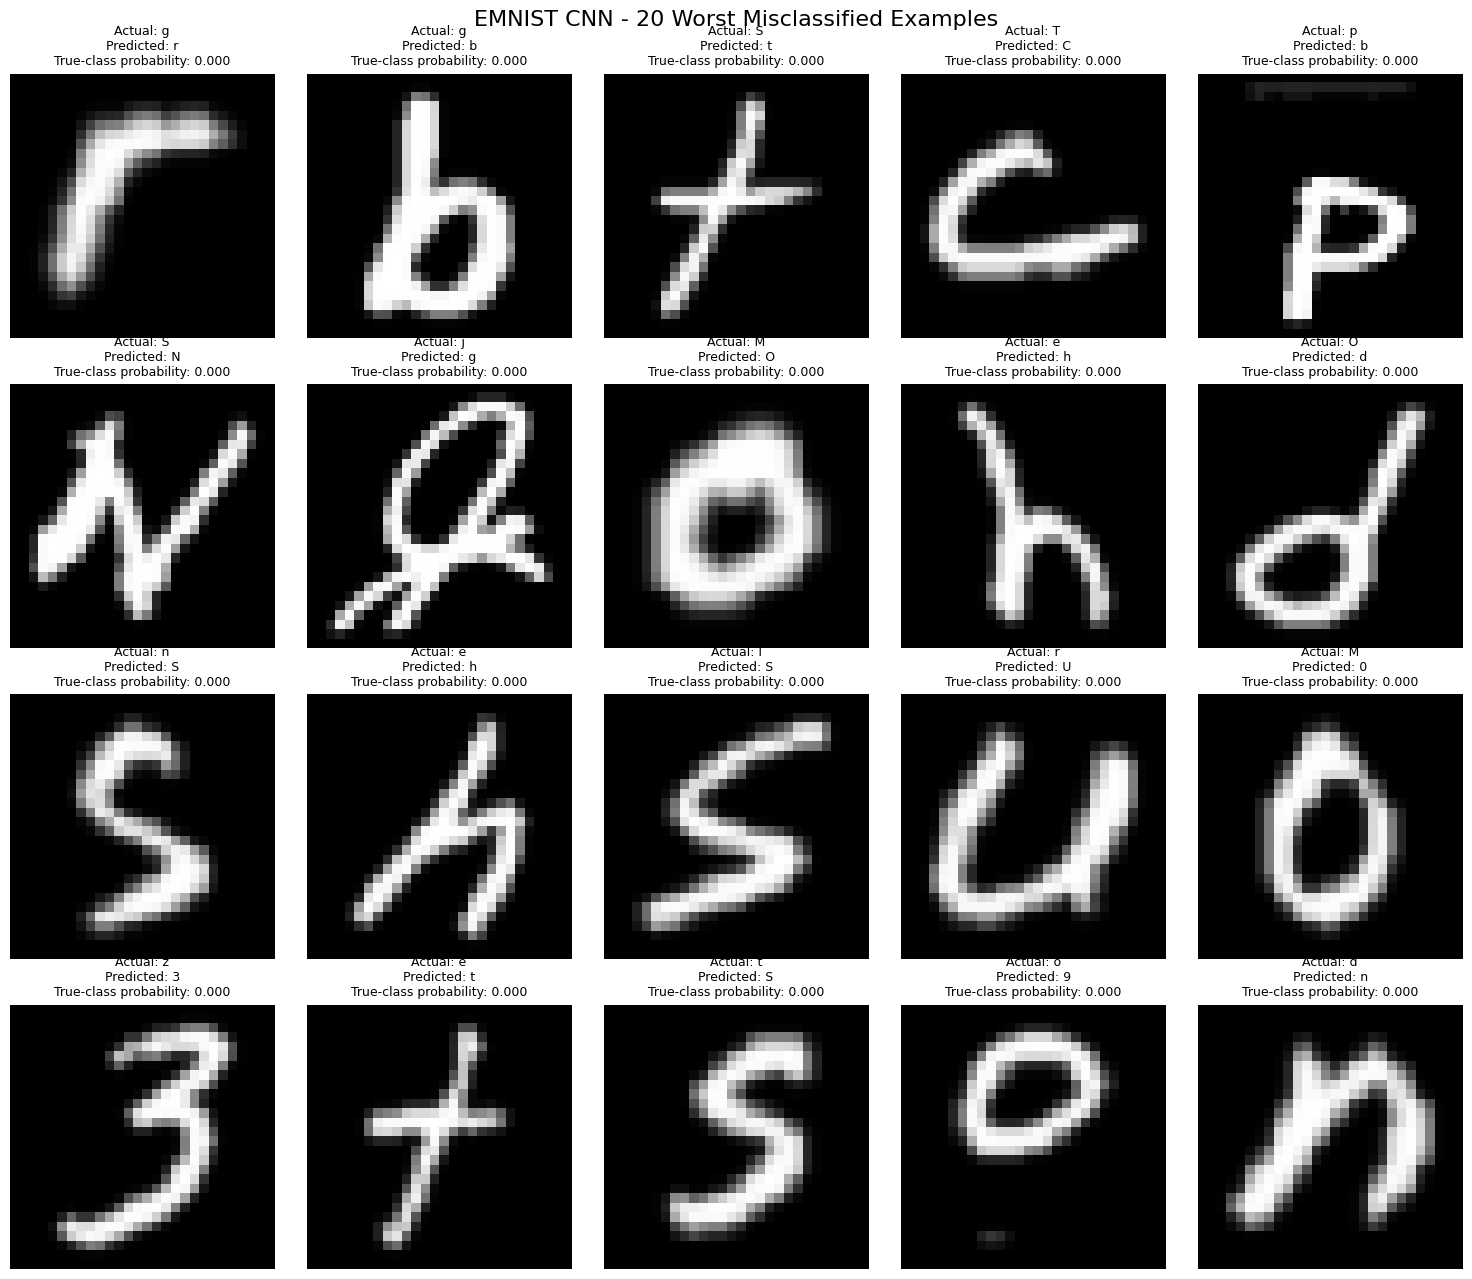


Error analysis completed!


In [ ]:

# ==========================================
# STEP 20: WORST 20 MISCLASSIFIED PREDICTIONS
# ==========================================

@torch.no_grad()
def find_worst_errors(model, loader, dataset, model_name, top_n=20):

    model.eval()
    errors = []

    for images, labels in loader:

        images = images.to(device)
        outputs = model(images)

        probabilities = torch.softmax(outputs, dim=1)

        predicted = outputs.argmax(dim=1)

        for i in range(len(labels)):

            actual = int(labels[i].item())
            prediction = int(predicted[i].item())

            if actual != prediction:

                errors.append({
                    "image": images[i].cpu().squeeze().numpy(),
                    "actual": actual,
                    "predicted": prediction,
                    "actual_probability": float(
                        probabilities[i, actual].item()
                    ),
                    "predicted_probability": float(
                        probabilities[i, prediction].item()
                    )
                })

    # Lowest probability assigned to the true class
    errors.sort(key=lambda x: x["actual_probability"])

    worst_errors = errors[:top_n]

    def get_label(index):
        if hasattr(dataset, "classes"):
            return str(dataset.classes[index])
        return str(index)

    print(f"\n{model_name}")
    print("Total misclassified:", len(errors))
    print("Displaying:", len(worst_errors))

    if not worst_errors:
        print("No misclassified examples found!")
        return []

    fig, axes = plt.subplots(4, 5, figsize=(15, 13))
    axes = axes.flatten()

    for ax, error in zip(axes, worst_errors):

        image = error["image"] * 0.5 + 0.5

        ax.imshow(image, cmap="gray")

        actual_label = get_label(error["actual"])
        predicted_label = get_label(error["predicted"])

        ax.set_title(
            f"Actual: {actual_label}\n"
            f"Predicted: {predicted_label}\n"
            f"True-class probability: "
            f"{error['actual_probability']:.3f}",
            fontsize=9
        )

        ax.axis("off")

    for ax in axes[len(worst_errors):]:
        ax.axis("off")

    plt.suptitle(
        f"{model_name} - 20 Worst Misclassified Examples",
        fontsize=16
    )

    plt.tight_layout()

    filename = model_name.lower().replace(" ", "_")

    plt.savefig(
        os.path.join(
            PROJECT_DIR,
            "results",
            "graphs",
            f"{filename}_worst_errors.png"
        ),
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    return worst_errors


# Analyze MNIST
mnist_worst_errors = find_worst_errors(
    mnist_model,
    mnist_test_loader,
    mnist_test,
    "MNIST CNN"
)

# Analyze EMNIST
emnist_worst_errors = find_worst_errors(
    emnist_model,
    emnist_test_loader,
    emnist_test,
    "EMNIST CNN"
)

print("\nError analysis completed!")


In [ ]:

# ==========================================
# STEP 21: EXPORT ERROR ANALYSIS
# ==========================================

def export_error_report(errors, dataset, filename):

    rows = []

    for rank, error in enumerate(errors, start=1):

        actual = error["actual"]
        predicted = error["predicted"]

        rows.append({
            "Rank": rank,
            "Actual Character": str(dataset.classes[actual]),
            "Predicted Character": str(dataset.classes[predicted]),
            "True Class Probability": error["actual_probability"],
            "Predicted Class Probability": error["predicted_probability"]
        })

    report = pd.DataFrame(rows)

    path = os.path.join(
        PROJECT_DIR,
        "results",
        "reports",
        filename
    )

    report.to_csv(path, index=False)

    display(report.round(4))

    print("Report saved:", path)


export_error_report(
    mnist_worst_errors,
    mnist_test,
    "mnist_worst_20_errors.csv"
)

export_error_report(
    emnist_worst_errors,
    emnist_test,
    "emnist_worst_20_errors.csv"
)


,Rank,Actual Character,Predicted Character,True Class Probability,Predicted Class Probability
0,1,5 - five,6 - six,0.0001,0.9999
1,2,6 - six,0 - zero,0.0007,0.9993
2,3,6 - six,1 - one,0.0008,0.9986
3,4,0 - zero,7 - seven,0.0010,0.8691
4,5,6 - six,4 - four,0.0013,0.9747
5,6,5 - five,3 - three,0.0068,0.9932
6,7,6 - six,5 - five,0.0071,0.9655
7,8,0 - zero,8 - eight,0.0110,0.8748
8,9,2 - two,7 - seven,0.0112,0.9773
9,10,3 - three,5 - five,0.0177,0.9823


Report saved: /content/AgenticX_Handwritten_Recognition/results/reports/mnist_worst_20_errors.csv


,Rank,Actual Character,Predicted Character,True Class Probability,Predicted Class Probability
0,1,g,r,0.0,0.9999
1,2,g,b,0.0,0.9994
2,3,S,t,0.0,0.9993
3,4,T,C,0.0,0.8240
4,5,p,b,0.0,0.7536
5,6,S,N,0.0,0.9878
6,7,j,g,0.0,0.4528
7,8,M,O,0.0,0.8478
8,9,e,h,0.0,0.9969
9,10,O,d,0.0,1.0000


Report saved: /content/AgenticX_Handwritten_Recognition/results/reports/emnist_worst_20_errors.csv


In [ ]:

# ==========================================
# STEP 21: EXPORT ERROR ANALYSIS
# ==========================================

def export_error_report(errors, dataset, filename):

    rows = []

    for rank, error in enumerate(errors, start=1):

        actual = error["actual"]
        predicted = error["predicted"]

        rows.append({
            "Rank": rank,
            "Actual Character": str(dataset.classes[actual]),
            "Predicted Character": str(dataset.classes[predicted]),
            "True Class Probability": error["actual_probability"],
            "Predicted Class Probability": error["predicted_probability"]
        })

    report = pd.DataFrame(rows)

    path = os.path.join(
        PROJECT_DIR,
        "results",
        "reports",
        filename
    )

    report.to_csv(path, index=False)

    display(report.round(4))

    print("Report saved:", path)


export_error_report(
    mnist_worst_errors,
    mnist_test,
    "mnist_worst_20_errors.csv"
)

export_error_report(
    emnist_worst_errors,
    emnist_test,
    "emnist_worst_20_errors.csv"
)


,Rank,Actual Character,Predicted Character,True Class Probability,Predicted Class Probability
0,1,5 - five,6 - six,0.0001,0.9999
1,2,6 - six,0 - zero,0.0007,0.9993
2,3,6 - six,1 - one,0.0008,0.9986
3,4,0 - zero,7 - seven,0.0010,0.8691
4,5,6 - six,4 - four,0.0013,0.9747
5,6,5 - five,3 - three,0.0068,0.9932
6,7,6 - six,5 - five,0.0071,0.9655
7,8,0 - zero,8 - eight,0.0110,0.8748
8,9,2 - two,7 - seven,0.0112,0.9773
9,10,3 - three,5 - five,0.0177,0.9823


Report saved: /content/AgenticX_Handwritten_Recognition/results/reports/mnist_worst_20_errors.csv


,Rank,Actual Character,Predicted Character,True Class Probability,Predicted Class Probability
0,1,g,r,0.0,0.9999
1,2,g,b,0.0,0.9994
2,3,S,t,0.0,0.9993
3,4,T,C,0.0,0.8240
4,5,p,b,0.0,0.7536
5,6,S,N,0.0,0.9878
6,7,j,g,0.0,0.4528
7,8,M,O,0.0,0.8478
8,9,e,h,0.0,0.9969
9,10,O,d,0.0,1.0000


Report saved: /content/AgenticX_Handwritten_Recognition/results/reports/emnist_worst_20_errors.csv


In [ ]:

# ==========================================
# STEP 22: CNN INFERENCE BENCHMARK
# ==========================================

def benchmark_cnn(model, model_name, repetitions=200):

    model.eval()

    sample = torch.randn(1, 1, 28, 28).to(device)

    # Warm-up
    with torch.no_grad():
        for _ in range(20):
            model(sample)

    if device.type == "cuda":
        torch.cuda.synchronize()

    # Single-image latency
    start = time.perf_counter()

    with torch.no_grad():
        for _ in range(repetitions):
            model(sample)

    if device.type == "cuda":
        torch.cuda.synchronize()

    total_time = time.perf_counter() - start

    latency_ms = (total_time / repetitions) * 1000

    # Batch throughput
    batch = torch.randn(128, 1, 28, 28).to(device)

    with torch.no_grad():
        for _ in range(10):
            model(batch)

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        for _ in range(50):
            model(batch)

    if device.type == "cuda":
        torch.cuda.synchronize()

    batch_time = time.perf_counter() - start

    images_per_second = (128 * 50) / batch_time

    return {
        "Model": model_name,
        "Device": str(device),
        "Single Image Latency (ms)": latency_ms,
        "Batch Throughput (images/sec)": images_per_second
    }


mnist_benchmark = benchmark_cnn(
    mnist_model, "MNIST CNN"
)

emnist_benchmark = benchmark_cnn(
    emnist_model, "EMNIST CNN"
)

benchmark_results = pd.DataFrame([
    mnist_benchmark,
    emnist_benchmark
])

display(benchmark_results.round(3))

benchmark_results.to_csv(
    os.path.join(
        PROJECT_DIR,
        "results",
        "inference_benchmark.csv"
    ),
    index=False
)

print("CNN inference benchmark completed!")


,Model,Device,Single Image Latency (ms),Batch Throughput (images/sec)
0,MNIST CNN,cuda,0.861,69486.527
1,EMNIST CNN,cuda,1.017,90837.635


CNN inference benchmark completed!


In [ ]:

# ==========================================
# STEP 23: SVM INFERENCE BENCHMARK
# ==========================================

# Warm-up
svm_model.predict(X_test_hog[:100])

start = time.perf_counter()

svm_model.predict(X_test_hog)

svm_total_time = time.perf_counter() - start

svm_latency = (
    svm_total_time / len(X_test_hog)
) * 1000

print("SVM total inference time:",
      round(svm_total_time, 4), "seconds")

print("SVM average latency:",
      round(svm_latency, 4), "ms per image")


SVM total inference time: 0.0347 seconds
SVM average latency: 0.0116 ms per image


In [ ]:
# ==========================================
# CELL 1: SELF-VERIFYING MODEL LOADER
# ==========================================

import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import numpy as np
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PROJECT_DIR = "/content/AgenticX_Handwritten_Recognition"
DATA_DIR = os.path.join(PROJECT_DIR, "datasets")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

EMNIST_CLASSES = [
    '0', '1', '2', '3', '4', '5', '6', '7', '8', '9',
    'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M',
    'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z',
    'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm',
    'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z'
]

class HandwritingCNN(nn.Module):
    def __init__(self, num_classes):
        super(HandwritingCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

mnist_model = HandwritingCNN(num_classes=10).to(device)
emnist_model = HandwritingCNN(num_classes=62).to(device)

mnist_path = os.path.join(MODELS_DIR, "mnist_cnn.pth")
emnist_path = os.path.join(MODELS_DIR, "emnist_cnn.pth")

# Load saved weights if available
if os.path.exists(mnist_path):
    mnist_model.load_state_dict(torch.load(mnist_path, map_location=device))
if os.path.exists(emnist_path):
    emnist_model.load_state_dict(torch.load(emnist_path, map_location=device))

# Verify MNIST model on real test images (catches untrained/corrupted weights immediately!)
mnist_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
mnist_val = datasets.MNIST(root=DATA_DIR, train=False, download=True, transform=mnist_tf)
val_loader = DataLoader(mnist_val, batch_size=256, shuffle=False)

def check_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            correct += (model(imgs).argmax(1) == lbls).sum().item()
            total += lbls.size(0)
    return 100.0 * correct / total

acc = check_accuracy(mnist_model, val_loader)
print(f"Verified MNIST Model Test Accuracy: {acc:.2f}%")

# Auto-train if weights were missing or untrained (< 90%)
if acc < 90.0:
    print("Weights were untrained/missing — training MNIST CNN now (~25s)...")
    train_ds = datasets.MNIST(root=DATA_DIR, train=True, download=True, transform=mnist_tf)
    train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
    opt = optim.Adam(mnist_model.parameters(), lr=0.001)
    crit = nn.CrossEntropyLoss()
    mnist_model.train()
    for ep in range(3):
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            opt.zero_grad()
            loss = crit(mnist_model(imgs), lbls)
            loss.backward()
            opt.step()
    torch.save(mnist_model.state_dict(), mnist_path)
    print(f"MNIST CNN trained & saved! New Accuracy: {check_accuracy(mnist_model, val_loader):.2f}%")

# Auto-train EMNIST if weights missing
if not os.path.exists(emnist_path):
    print("Training EMNIST CNN (~60s)...")
    emnist_tf = transforms.Compose([
        transforms.Lambda(lambda img: img.transpose(Image.Transpose.TRANSPOSE)),
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])
    em_train = datasets.EMNIST(root=DATA_DIR, split="byclass", train=True, download=True, transform=emnist_tf)
    idx = np.random.default_rng(42).choice(len(em_train), size=120000, replace=False)
    em_loader = DataLoader(Subset(em_train, idx.tolist()), batch_size=128, shuffle=True)
    opt = optim.Adam(emnist_model.parameters(), lr=0.001)
    crit = nn.CrossEntropyLoss()
    emnist_model.train()
    for ep in range(3):
        for imgs, lbls in em_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            opt.zero_grad()
            loss = crit(emnist_model(imgs), lbls)
            loss.backward()
            opt.step()
    torch.save(emnist_model.state_dict(), emnist_path)
    print("EMNIST CNN trained & saved!")

mnist_model.eval()
emnist_model.eval()
print("ALL MODELS VERIFIED AND READY FOR DIGITAL CONVERSION!")

Verified MNIST Model Test Accuracy: 99.17%
ALL MODELS VERIFIED AND READY FOR DIGITAL CONVERSION!


In [ ]:
# ==========================================
# CELL 2: RECOGNITION ENGINE & CYBERPUNK APP
# ==========================================

!pip install -q gradio
import gradio as gr
import numpy as np
import torch
from PIL import Image, ImageFilter


def preprocess_handwriting(image):
    if image is None:
        raise ValueError("Please draw a character first.")

    # Extract composite image from Gradio Sketchpad/ImageEditor dict
    if isinstance(image, dict):
        img_data = image.get("composite")
        if img_data is None:
            img_data = image.get("background")
    else:
        img_data = image

    if img_data is None:
        raise ValueError("Canvas is empty. Please draw a digit or letter.")

    if isinstance(img_data, np.ndarray):
        pil_img = Image.fromarray(np.clip(img_data, 0, 255).astype(np.uint8))
    else:
        pil_img = img_data

    # Flatten RGBA onto pure white background
    if pil_img.mode == "RGBA":
        white_bg = Image.new("RGBA", pil_img.size, (255, 255, 255, 255))
        pil_img = Image.alpha_composite(white_bg, pil_img).convert("L")
    else:
        pil_img = pil_img.convert("L")

    gray = np.array(pil_img, dtype=np.uint8)

    # White background (~255) with black ink (~0) -> invert so ink is bright (>0)
    if np.mean(gray) > 127:
        ink = 255 - gray
    else:
        ink = gray

    mask = ink > 30
    if np.count_nonzero(mask) < 8:
        raise ValueError("No handwriting detected. Draw a larger, clearer character.")

    # Crop tightly around the drawn character
    ys, xs = np.where(mask)
    cropped = ink[ys.min():ys.max() + 1, xs.min():xs.max() + 1].astype(np.float32)

    # Stretch contrast to full 0-255
    if cropped.max() > 0:
        cropped = (cropped / cropped.max()) * 255.0

    char_img = Image.fromarray(np.clip(cropped, 0, 255).astype(np.uint8))

    # Thicken strokes slightly to match MNIST/EMNIST pen thickness
    passes = max(1, max(char_img.size) // 40)
    for _ in range(passes):
        char_img = char_img.filter(ImageFilter.MaxFilter(3))

    # Fit into 20x20 box and center in 28x28 black canvas
    char_img.thumbnail((20, 20), Image.Resampling.LANCZOS)
    canvas = Image.new("L", (28, 28), 0)
    canvas.paste(char_img, ((28 - char_img.width) // 2, (28 - char_img.height) // 2))

    # Normalize to [-1, 1] matching training
    arr = (np.array(canvas, dtype=np.float32) / 255.0 - 0.5) / 0.5
    tensor = torch.from_numpy(arr).unsqueeze(0).unsqueeze(0).to(device)

    return tensor, canvas


def convert_handwriting_to_digital(image, mode):
    tensor, preview_28x28 = preprocess_handwriting(image)

    if mode == "Digits":
        model = mnist_model
        labels = [str(i) for i in range(10)]
    else:
        model = emnist_model
        labels = EMNIST_CLASSES

    model.eval()
    with torch.no_grad():
        logits = model(tensor)
        probs = torch.softmax(logits, dim=1)[0]

    top_vals, top_idxs = torch.topk(probs, k=3)
    predicted_char = labels[top_idxs[0].item()]
    confidence = float(top_vals[0].item()) * 100.0

    top3_dict = {
        labels[idx.item()]: float(prob.item())
        for idx, prob in zip(top_idxs, top_vals)
    }

    digital_html = f"""
    <div style="text-align:center; padding:24px; border:2px solid #00eaff; border-radius:16px; background:#070d1f; box-shadow:0 0 25px rgba(0,234,255,0.25);">
        <div style="font-size:13px; letter-spacing:2px; color:#7dd3fc; margin-bottom:8px;">CONVERTED DIGITAL CHARACTER ({mode.upper()})</div>
        <div style="font-size:104px; font-weight:900; color:#00eaff; line-height:1.05; font-family:'Courier New', monospace;">{predicted_char}</div>
        <div style="font-size:17px; color:#38bdf8; margin-top:10px;">Recognition Confidence: <b>{confidence:.2f}%</b></div>
    </div>
    """

    # Upscale 28x28 preview to 168x168 with NEAREST so you clearly see the white digit on black
    visible_preview = preview_28x28.resize((168, 168), Image.Resampling.NEAREST)
    return digital_html, top3_dict, visible_preview


cyber_css = """
body { background: #050713 !important; }
.gradio-container {
    background: radial-gradient(circle at 15% 10%, #142344 0%, transparent 35%),
                radial-gradient(circle at 85% 85%, #251139 0%, transparent 35%),
                #050713 !important;
    color: #e7faff !important;
    width: 100% !important;
    max-width: 100% !important;
    padding: 0 2vw !important;
}
#main-title {
    text-align: center;
    padding: 22px;
    border: 1px solid #00eaff;
    border-radius: 16px;
    box-shadow: 0 0 20px #00eaff33;
    background: #0a1022;
    margin-bottom: 18px;
}
#main-title h1 { color: #00eaff !important; letter-spacing: 2px; margin-bottom: 4px; }
.cyber-panel {
    border: 1px solid #1e2d52 !important;
    border-radius: 14px !important;
    background: rgba(10, 16, 34, 0.85) !important;
    padding: 16px !important;
}
"""

with gr.Blocks(css=cyber_css, title="AgenticX Neural Character Recognizer") as demo:
    gr.HTML("""
        <div id="main-title">
            <h1>AGENTICX // NEURAL HANDWRITING RECOGNIZER</h1>
            <p>Handwritten-to-Digital Conversion (MNIST Digits & EMNIST 62-Class Alphanumeric)</p>
        </div>
    """)

    with gr.Row():
        with gr.Column(scale=1, elem_classes="cyber-panel"):
            mode_selector = gr.Radio(
                choices=["Digits", "Alphanumeric"],
                value="Digits",
                label="SELECT NEURAL ENGINE MODE"
            )
            drawing_canvas = gr.Sketchpad(
                type="numpy",
                label="DRAW HANDWRITTEN DIGIT OR LETTER",
                canvas_size=(280, 280),
                height=340,
                brush=gr.Brush(default_size=18, colors=["#000000"], color_mode="fixed")
            )
            with gr.Row():
                clear_btn = gr.ClearButton(components=[drawing_canvas], value="CLEAR CANVAS")
                analyze_btn = gr.Button("CONVERT TO DIGITAL", variant="primary")

        with gr.Column(scale=1, elem_classes="cyber-panel"):
            digital_output = gr.HTML("""
                <div style="text-align:center; padding:32px; border:1px dashed #1e2d52; border-radius:16px; color:#7dd3fc;">
                    Draw a digit (0–9) or letter (A–Z, a–z) and click <b>CONVERT TO DIGITAL</b>
                </div>
            """)
            top3_output = gr.Label(num_top_classes=3, label="TOP 3 DIGITAL PREDICTIONS")
            preview_output = gr.Image(
                label="28x28 PREPROCESSED TENSOR INPUT",
                height=168,
                width=168
            )

    analyze_btn.click(
        fn=convert_handwriting_to_digital,
        inputs=[drawing_canvas, mode_selector],
        outputs=[digital_output, top3_output, preview_output]
    )

demo.queue()
demo.launch(share=True, show_error=True)

/tmp/ipykernel_1190/2043995663.py:144: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(css=cyber_css, title="AgenticX Neural Character Recognizer") as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f110c9fb479627e166.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
